# 05 · Customer value: which channels bring customers who come back?

**Why this matters, simply:** a channel can look cheap because its first sale is cheap, yet bring
customers who never return. Another can look expensive but bring loyal customers. A CFO cutting
budget needs both views: today's sale *and* the customer's future value.

**What this notebook does (Q4):**
1. **Survival curves:** how fast each channel's customers place a second order (Kaplan–Meier,
   log-rank test, Cox model controlling for first-order value).
2. **Lifetime value (CLV):** expected discounted contribution per new customer over 12 and 24 months
   (BG/NBD for how often they buy, Gamma–Gamma for how much each order earns), with 90% intervals.
3. **CAC, CAC:CLV and payback** by channel.
4. **CLV-adjusted ROI:** combine MMM v2's short-term return with the future value of the customers
   each channel brings, and see whether the ranking changes.

Data: `customers.csv` / `orders.csv` (1-in-8 sample of website customers, weeks 1–104).
Quick-commerce ads drive app sales, not website customers, so they have no website CLV here.

In [ ]:
# Colab set-up: run this first (skipped automatically outside Colab)
import sys, os
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/anvesha2402/prakriti-growth-measurement.git"   # change if your repo differs
    if not os.path.exists("/content/repo"):
        get_ipython().system(f"git clone {REPO_URL} /content/repo")
    os.chdir("/content/repo")
    get_ipython().system("pip install -q 'pymc-marketing==1.1.*' statsmodels h5netcdf")


In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test
from pymc_marketing.clv import BetaGeoModel, GammaGammaModel, rfm_summary
from common import load, FULL, CHANNELS, LABEL, COLOR, INK, INK2, NEUTRAL, style, save, ROOT

style()
SAMPLE = 8                                  # customers.csv is a 1-in-8 sample
END = pd.Timestamp("2026-10-04")            # last day of week 104
ANNUAL_DISCOUNT = 0.12
cust = pd.read_csv(FULL / "customers.csv", parse_dates=["first_order_date"])
orders = pd.read_csv(FULL / "orders.csv", parse_dates=["date"]).merge(cust[["customer_id", "acquisition_channel", "geo"]])
ACQ = ["influencer", "youtube", "organic", "search", "meta", "trade_promo"]
ALABEL = {**LABEL, "organic": "Organic"}
ACOLOR = {**COLOR, "organic": NEUTRAL}
print(f"{len(cust):,} customers, {len(orders):,} orders, {orders.date.min():%d %b %Y} – {orders.date.max():%d %b %Y}")

35,411 customers, 77,834 orders, 07 Oct 2024 – 04 Oct 2026


## 1. Survival: how quickly does each channel's customer come back?
The "event" is the second order. Customers with no second order by 4 Oct 2026 are *censored*:
we only know they had not returned yet.

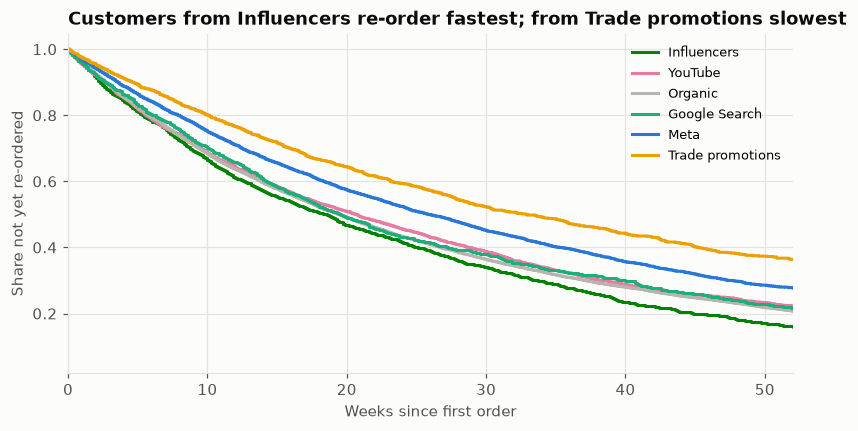

Log-rank test across channels: chi² = 319.0, p < 0.001


,median weeks to 2nd order,90-day repeat rate
Google Search,19.57,0.37
Influencers,18.43,0.40
Meta,25.86,0.31
Organic,19.43,0.39
Trade promotions,32.86,0.25
YouTube,20.71,0.38


In [2]:
o = orders.sort_values(["customer_id", "date"])
o["n"] = o.groupby("customer_id").cumcount()
first = o[o.n == 0].set_index("customer_id")
second = o[o.n == 1].set_index("customer_id")["date"]
surv = first[["date", "acquisition_channel", "gross_value_inr", "geo"]].rename(columns={"date": "first_date"})
surv["second_date"] = second.reindex(surv.index)
surv["event"] = surv["second_date"].notna().astype(int)
surv["weeks"] = ((surv["second_date"].fillna(END) - surv["first_date"]).dt.days / 7).clip(lower=0.1)

fig, ax = plt.subplots(figsize=(8.5, 4))
kmf = KaplanMeierFitter()
med = {}
for a in ACQ:
    d = surv[surv.acquisition_channel == a]
    kmf.fit(d.weeks, d.event, label=ALABEL[a])
    kmf.plot_survival_function(ax=ax, ci_show=False, color=ACOLOR[a], lw=2)
    med[ALABEL[a]] = kmf.median_survival_time_
ax.set_xlim(0, 52); ax.set_xlabel("Weeks since first order"); ax.set_ylabel("Share not yet re-ordered")
ax.legend(frameon=False, fontsize=8.5)
_rank = sorted(med, key=lambda k: med[k])
ax.set_title(f"Customers from {_rank[0]} re-order fastest; from {_rank[-1]} slowest")
save(fig, "05_km_second_order"); plt.show()

lr = multivariate_logrank_test(surv.weeks, surv.acquisition_channel, surv.event)
print(f"Log-rank test across channels: chi² = {lr.test_statistic:.1f}, p {'< 0.001' if lr.p_value < 0.001 else f'= {lr.p_value:.3f}'}")
rep90 = surv[surv.first_date <= END - pd.Timedelta(days=91)].assign(r90=lambda d: (d.event == 1) & (d.weeks <= 13))
pd.DataFrame({"median weeks to 2nd order": pd.Series(med),
              "90-day repeat rate": rep90.groupby("acquisition_channel").r90.mean().rename(ALABEL)}).round(2)

**Cox model:** does the channel still matter once we allow for how big the first order was?
Hazard ratio > 1 = returns faster than organic customers.

In [3]:
cx = pd.get_dummies(surv[["weeks", "event", "acquisition_channel"]], columns=["acquisition_channel"], dtype=float)
cx = cx.drop(columns="acquisition_channel_organic")
cx["log_first_order_value"] = np.log(surv["gross_value_inr"])
cph = CoxPHFitter().fit(cx, duration_col="weeks", event_col="event")
hr = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
hr.index = [ALABEL.get(i.replace("acquisition_channel_", ""), i) for i in hr.index]
hr.round(3)

,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
Influencers,1.095,1.041,1.151,0.000
Meta,0.793,0.762,0.826,0.000
Google Search,0.966,0.908,1.028,0.280
Trade promotions,0.638,0.598,0.682,0.000
YouTube,0.958,0.915,1.002,0.063
log_first_order_value,0.998,0.974,1.024,0.905


## 2. Lifetime value with BG/NBD + Gamma–Gamma, by acquisition channel
- **BG/NBD:** while a customer is "alive" they buy at their own rate; after each repeat order there
  is a chance they stop for good.
- **Gamma–Gamma:** how much contribution each order earns.
- CLV = first-order contribution + discounted expected contribution from repeat orders (12% a year).

One model per channel, fitted by MCMC, so every CLV has a 90% interval.

In [4]:
d_month = (1 + ANNUAL_DISCOUNT) ** (1 / 12) - 1
WEEKS_PER_MONTH = 52 / 12
first_contrib = first.groupby("acquisition_channel")["contribution_inr"].mean()
CACHE = ROOT / "model" / "clv_fit_cache.npz"      # BG/NBD + Gamma-Gamma draws (slow to fit), reused on re-runs
clv_draws, curves, fit_info = {}, {}, {}
if CACHE.exists():
    z = np.load(CACHE, allow_pickle=True)
    clv_draws = z["clv_draws"].item(); curves = z["curves"].item()
    print("Loaded fitted CLV draws from cache")
else:
    for a in ACQ:
        sub = orders[orders.acquisition_channel == a]
        rfm = rfm_summary(sub, "customer_id", "date", "contribution_inr", observation_period_end=END, time_unit="W")
        bg = BetaGeoModel(sampler_config=dict(draws=500, tune=500, chains=2, progressbar=False, random_seed=7))
        bg.fit(data=rfm[["customer_id", "frequency", "recency", "T"]])
        gg = GammaGammaModel(sampler_config=dict(draws=500, tune=500, chains=2, progressbar=False, random_seed=7))
        gg.fit(data=rfm[rfm.frequency > 0][["customer_id", "frequency", "monetary_value"]])
        spend = gg.expected_new_customer_spend().stack(s=("chain", "draw")).values            # contribution per repeat order
        cum = np.array([bg.expected_purchases_new_customer(t=m * WEEKS_PER_MONTH).isel(customer_id=0)
                        .stack(s=("chain", "draw")).values for m in range(0, 25)])           # (months, draws)
        inc = np.diff(cum, axis=0)                                                          # expected repeat orders in each month
        disc = (1 + d_month) ** -np.arange(1, 25)
        clv_draws[a] = first_contrib[a] + np.cumsum(inc * spend[None, :] * disc[:, None], axis=0)   # (24 months, draws)
        curves[a] = np.median(first_contrib[a] + np.cumsum(inc * spend[None, :], axis=0), axis=1)   # undiscounted, for payback
        print(f"{ALABEL[a]:16s} fitted on {len(rfm):,} customers ({(rfm.frequency > 0).mean():.0%} repeat)")
    np.savez_compressed(CACHE, clv_draws=np.array(clv_draws, dtype=object), curves=np.array(curves, dtype=object))

clv = pd.DataFrame({ALABEL[a]: {
    "first-order contribution ₹": first_contrib[a],
    "CLV 12m ₹": np.median(clv_draws[a][11]), "CLV 12m low": np.quantile(clv_draws[a][11], .05), "CLV 12m high": np.quantile(clv_draws[a][11], .95),
    "CLV 24m ₹": np.median(clv_draws[a][23]), "CLV 24m low": np.quantile(clv_draws[a][23], .05), "CLV 24m high": np.quantile(clv_draws[a][23], .95),
} for a in ACQ}).T
clv.round(0)

Loaded fitted CLV draws from cache


,first-order contribution ₹,CLV 12m ₹,CLV 12m low,CLV 12m high,CLV 24m ₹,CLV 24m low,CLV 24m high
Influencers,270.0,776.0,753.0,802.0,1035.0,998.0,1082.0
YouTube,259.0,685.0,670.0,704.0,910.0,881.0,940.0
Organic,261.0,647.0,642.0,653.0,843.0,833.0,852.0
Google Search,257.0,651.0,629.0,676.0,831.0,793.0,875.0
Meta,249.0,559.0,549.0,569.0,717.0,700.0,736.0
Trade promotions,183.0,362.0,352.0,374.0,430.0,416.0,449.0


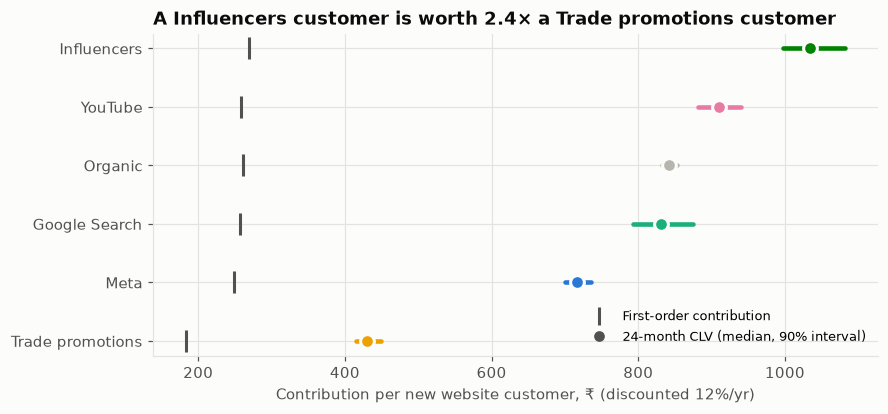

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
order_ = clv.sort_values("CLV 24m ₹").index
for j, name in enumerate(order_):
    a = [k for k, v in ALABEL.items() if v == name][0]
    r = clv.loc[name]
    ax.plot([r["CLV 24m low"], r["CLV 24m high"]], [j, j], color=ACOLOR[a], lw=3, solid_capstyle="round")
    ax.plot(r["CLV 24m ₹"], j, "o", color=ACOLOR[a], ms=9, mec="#fcfcfb", mew=2)
    ax.plot(r["first-order contribution ₹"], j, "|", color=INK2, ms=14, mew=2)
ax.plot([], [], "|", color=INK2, ms=12, mew=2, label="First-order contribution")
ax.plot([], [], "o", color=INK2, label="24-month CLV (median, 90% interval)")
ax.set_yticks(range(len(order_)), order_)
ax.set_xlabel("Contribution per new website customer, ₹ (discounted 12%/yr)")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
_hi, _lo = clv["CLV 24m ₹"].idxmax(), clv["CLV 24m ₹"].idxmin()
ax.set_title(f"A {_hi} customer is worth {clv.loc[_hi, 'CLV 24m ₹'] / clv.loc[_lo, 'CLV 24m ₹']:.1f}× a {_lo} customer")
save(fig, "05_clv_by_channel"); plt.show()

## 3. CAC, CAC:CLV and payback
Most ad spend drives app and store sales, so only the **website share of each channel's spend**
(website ≈ 20% of revenue) is charged to website customers. The sample is scaled ×8 to full volume.
Window: weeks 1–96, to match MMM v2.

In [6]:
w, _ = load(FULL)
w96 = w[w.week <= 96]
web_share = w96.rev_website_lakh.sum() / w96.revenue_lakh.sum()
cust96 = cust[cust.first_order_date <= pd.Timestamp("2026-08-09")]                  # end of week 96
n_cust = cust96.acquisition_channel.value_counts() * SAMPLE
rows = []
for a in [x for x in ACQ if x != "organic"]:
    spend = w96[f"spend_{a}_lakh"].sum() * 1e5
    cac = spend * web_share / n_cust[a]
    pay = next((m + 1 for m, v in enumerate(curves[a]) if v >= cac), None)
    rows.append(dict(channel=ALABEL[a], new_customers=n_cust[a], CAC=cac, CLV_24m=clv.loc[ALABEL[a], "CLV 24m ₹"],
                     CLV_to_CAC=clv.loc[ALABEL[a], "CLV 24m ₹"] / cac, payback_months=pay if pay else ">24"))
cac_tbl = pd.DataFrame(rows).set_index("channel")
print(f"Website share of revenue used for CAC: {web_share:.1%}")
cac_tbl.round(2)

Website share of revenue used for CAC: 20.0%


,new_customers,CAC,CLV_24m,CLV_to_CAC,payback_months
channel,,,,,
Influencers,17832,581.72,1034.65,1.78,7
YouTube,23176,675.03,909.71,1.35,11
Google Search,11632,1358.28,831.04,0.61,>24
Meta,33256,809.06,717.09,0.89,>24
Trade promotions,12784,987.16,429.67,0.44,>24


## 4. CLV-adjusted ROI: does looking at customer value change the ranking?
- **Short-term contribution per ₹1** = MMM v2 ROI × blended contribution margin (37%).
  That margin is 45% quick commerce at 30% plus 55% other channels at 42%, from the benchmark register.
- **Future value per ₹1** = new website customers × (24-month CLV − first-order contribution) ÷ spend.
  This counts only repeat website orders, so it is conservative.
- **CLV-adjusted contribution per ₹1** = the two added together. Above ₹1 means the channel pays for itself.

In [7]:
BLENDED_MARGIN = 0.45 * 0.30 + 0.55 * 0.42
v2 = pd.read_csv(ROOT / "model" / "mmm_v2_roi.csv").set_index("channel")
adj = []
for c in CHANNELS:
    name = LABEL[c]
    spend = w96[f"spend_{c}_lakh"].sum() * 1e5
    short = v2.loc[name, "roi"] * BLENDED_MARGIN
    future = 0.0 if c == "qc_ads" else n_cust[c] * (clv.loc[name, "CLV 24m ₹"] - clv.loc[name, "first-order contribution ₹"]) / spend
    adj.append(dict(channel=name, key=c, mmm_v2_roi=v2.loc[name, "roi"], short_term_contribution_per_rs=short,
                    future_value_per_rs=future, clv_adjusted_contribution_per_rs=short + future))
adj = pd.DataFrame(adj).set_index("channel")
adj["rank_short_term"] = adj.mmm_v2_roi.rank(ascending=False).astype(int)
adj["rank_clv_adjusted"] = adj.clv_adjusted_contribution_per_rs.rank(ascending=False).astype(int)
adj.drop(columns="key").round(3)

,mmm_v2_roi,short_term_contribution_per_rs,future_value_per_rs,clv_adjusted_contribution_per_rs,rank_short_term,rank_clv_adjusted
channel,,,,,,
Meta,0.082,0.030,0.116,0.146,6,6
Quick-commerce ads,1.257,0.460,0.000,0.460,4,4
Google Search,0.933,0.342,0.085,0.426,5,5
Trade promotions,2.454,0.898,0.050,0.948,1,1
YouTube,1.327,0.486,0.193,0.679,3,3
Influencers,1.828,0.669,0.263,0.932,2,2


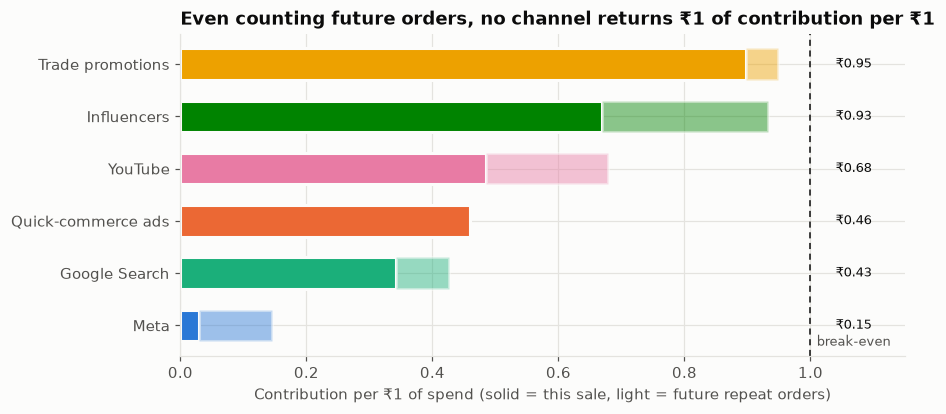

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
srt = adj.sort_values("clv_adjusted_contribution_per_rs")
for j, (name, r) in enumerate(srt.iterrows()):
    ax.barh(j, r.short_term_contribution_per_rs, color=COLOR[r.key], height=0.6, edgecolor="#fcfcfb", linewidth=2)
    ax.barh(j, r.future_value_per_rs, left=r.short_term_contribution_per_rs, color=COLOR[r.key], alpha=0.45,
            height=0.6, edgecolor="#fcfcfb", linewidth=2)
    ax.text(1.04, j, f"₹{r.clv_adjusted_contribution_per_rs:.2f}", va="center", fontsize=8.5, color=INK)
ax.axvline(1, color=INK, lw=1, ls=(0, (4, 3)))
ax.text(1.01, -0.45, "break-even", fontsize=8.5, color=INK2, va="bottom")
ax.set_yticks(range(len(srt)), srt.index)
ax.set_xlabel("Contribution per ₹1 of spend (solid = this sale, light = future repeat orders)")
ax.set_xlim(0, max(1.15, srt.clv_adjusted_contribution_per_rs.max() + 0.2))
_n = int((adj.clv_adjusted_contribution_per_rs >= 1).sum())
ax.set_title("Even counting future orders, no channel returns ₹1 of contribution per ₹1" if _n == 0
             else f"{_n} channel(s) pay for themselves once future orders count")
save(fig, "05_clv_adjusted_roi"); plt.show()

## 5. Save for the optimiser and the P&L

In [9]:
out = ROOT / "model"
clv.to_csv(out / "clv_by_channel.csv")
cac_tbl.to_csv(out / "cac_by_channel.csv")
adj.drop(columns="key").to_csv(out / "clv_adjusted_roi.csv")
print("Saved clv_by_channel.csv, cac_by_channel.csv, clv_adjusted_roi.csv")

Saved clv_by_channel.csv, cac_by_channel.csv, clv_adjusted_roi.csv


## 6. So what

In [10]:
best, worst = clv["CLV 24m ₹"].idxmax(), clv["CLV 24m ₹"].idxmin()
moved = adj[adj.rank_short_term != adj.rank_clv_adjusted]
pays = adj[adj.clv_adjusted_contribution_per_rs >= 1].index.tolist()
print("SO WHAT")
tp, inf_ = adj.loc["Trade promotions"], adj.loc["Influencers"]
print(f"1. Customer quality differs a lot: a customer acquired through {best} is worth ₹{clv.loc[best, 'CLV 24m ₹']:.0f} over 24 months, "
      f"one acquired through {worst} ₹{clv.loc[worst, 'CLV 24m ₹']:.0f} ({clv.loc[best, 'CLV 24m ₹'] / clv.loc[worst, 'CLV 24m ₹']:.1f}×). "
      f"Return speed differs by channel (log-rank p < 0.001), even after allowing for first-order value (Cox).")
print(f"2. The cheap-customer trap: Trade promotions lead on short-term ROI, but their customers have the lowest CLV "
      f"(₹{clv.loc['Trade promotions', 'CLV 24m ₹']:.0f}) and CLV:CAC of {cac_tbl.loc['Trade promotions', 'CLV_to_CAC']:.2f}. "
      f"Their lead over Influencers shrinks from ₹{tp.short_term_contribution_per_rs - inf_.short_term_contribution_per_rs:.2f} "
      f"to ₹{tp.clv_adjusted_contribution_per_rs - inf_.clv_adjusted_contribution_per_rs:.2f} per ₹1 once future orders count.")
print("3. Ranking changes after adding customer value: " +
      (", ".join(f"{n} #{int(r.rank_short_term)}→#{int(r.rank_clv_adjusted)}" for n, r in moved.iterrows()) or "none; the order holds, but the gaps narrow") + ".")
paid = cac_tbl[cac_tbl.payback_months != ">24"]
print(f"4. Payback within 24 months only for: {', '.join(f'{n} ({int(m)} months)' for n, m in paid.payback_months.items())}. "
      f"No channel returns ₹1 of contribution per ₹1 even with future orders "
      f"(best: {adj.clv_adjusted_contribution_per_rs.idxmax()} ₹{adj.clv_adjusted_contribution_per_rs.max():.2f}), so cutting to the 20% cap is "
      "financially sound; the optimiser (Stage F) decides where the cuts fall, using CLV-adjusted value.")

SO WHAT
1. Customer quality differs a lot: a customer acquired through Influencers is worth ₹1035 over 24 months, one acquired through Trade promotions ₹430 (2.4×). Return speed differs by channel (log-rank p < 0.001), even after allowing for first-order value (Cox).
2. The cheap-customer trap: Trade promotions lead on short-term ROI, but their customers have the lowest CLV (₹430) and CLV:CAC of 0.44. Their lead over Influencers shrinks from ₹0.23 to ₹0.02 per ₹1 once future orders count.
3. Ranking changes after adding customer value: none; the order holds, but the gaps narrow.
4. Payback within 24 months only for: Influencers (7 months), YouTube (11 months). No channel returns ₹1 of contribution per ₹1 even with future orders (best: Trade promotions ₹0.95), so cutting to the 20% cap is financially sound; the optimiser (Stage F) decides where the cuts fall, using CLV-adjusted value.
